# Assignment 3 — Think First, Then Code
**Linear, Logistic, and Softmax Regression for Software Engineering**

This notebook solves **both variants** of the assignment (V1 and V2 = "Variant B"). For every question the structure is the one required by the instructions: **Think first** (reasoning written before running anything) → **Code** (implementation and key outputs, rounded to three decimals) → **Comparison** with the initial expectation.

*Run order: top to bottom (Runtime → Run all). Only NumPy, Matplotlib and scikit-learn are needed.*

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, accuracy_score, log_loss

np.set_printoptions(precision=3, suppress=True)   # print arrays with 3 decimals

> **Note on logistic / softmax fitting.** In Q3 and Q6 the classes are perfectly separable, so the *unregularised* maximum-likelihood coefficients do not exist (they would grow to infinity). I therefore use scikit-learn's default **L2-regularised** fit (`C = 1`). This keeps the coefficients finite and the probabilities moderate; it does not change the signs or the predicted classes.

---
# VARIANT V1

## Part I — Linear Regression
### Question 1 — Code-review time
Pull-request size *x* (hundreds of changed lines) and review time *y* (min).

**Think first.**
- **(i) Input / target:** input *x* = PR size (hundreds of changed lines); target *y* = review time in minutes.
- **(ii) Sign of the slope:** **positive** — a larger PR has more code to read, so the review takes longer. Rough guess from the end points: (72 − 18) / 7 ≈ 7.7 min per additional 100 lines.
- **(iii) Which prediction is safer?** *x* = 5.5 lies **inside** the observed range [1, 8] (interpolation), so it is the safer one. *x* = 10 is **extrapolation**: nothing in the data guarantees the straight-line trend continues (very large PRs are often skimmed or split, so the trend may bend).

a) beta0 = 9.643, beta1 = 7.690
b) prediction at x = 5.5: 51.940   [inside the training range 1..8]
b) prediction at x = 10: 86.548   [OUTSIDE (extrapolation) the training range 1..8]
b) MSE = 0.435, R^2 = 0.999


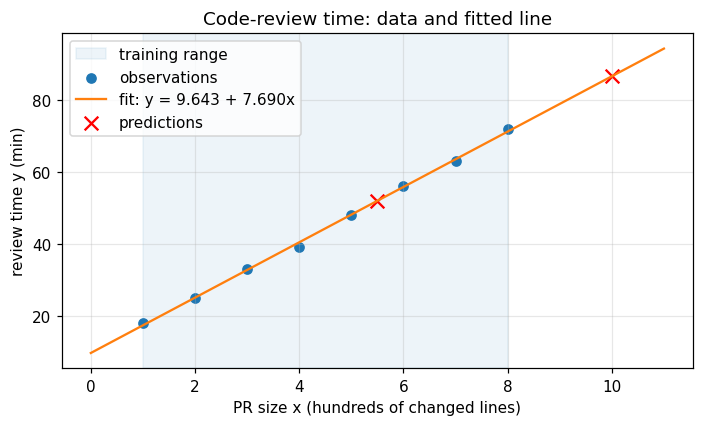

In [2]:
# Data
x = np.array(list(range(1, 9)), dtype=float)
y = np.array([18, 25, 33, 39, 48, 56, 63, 72], dtype=float)
points = [5.5, 10]

# a) Fit y_hat = b0 + b1*x with the normal equations (X^T X) b = X^T y
X = np.column_stack([np.ones_like(x), x])
b0, b1 = np.linalg.solve(X.T @ X, X.T @ y)
print(f"a) beta0 = {b0:.3f}, beta1 = {b1:.3f}")

# b) Predictions, MSE and R^2
yhat = X @ np.array([b0, b1])
mse = np.mean((y - yhat) ** 2)
r2 = 1 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2)
for xn in points:
    where = "inside" if x.min() <= xn <= x.max() else "OUTSIDE (extrapolation)"
    print(f"b) prediction at x = {xn}: {b0 + b1 * xn:.3f}   [{where} the training range {x.min():.0f}..{x.max():.0f}]")
print(f"b) MSE = {mse:.3f}, R^2 = {r2:.3f}")

xs = np.linspace(0, 11, 100)
plt.figure(figsize=(6.5, 4))
plt.axvspan(x.min(), x.max(), alpha=0.08, color="C0", label="training range")
plt.scatter(x, y, label="observations")
plt.plot(xs, b0 + b1 * xs, color="C1", label=f"fit: y = {b0:.3f} + {b1:.3f}x")
plt.scatter(points, [b0 + b1 * p for p in points], marker="x", color="red", s=80, label="predictions")
plt.xlabel("PR size x (hundreds of changed lines)"); plt.ylabel("review time y (min)"); plt.title("Code-review time: data and fitted line")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

**c) Comparison with the initial reasoning.**
- **Slope:** β₁ = 7.690 > 0 — positive as predicted and almost exactly the rough estimate (≈ 7.7). *Interpretation:* every extra 100 changed lines adds ≈ 7.690 min of review time. The intercept β₀ = 9.643 min is the fixed overhead of the line at *x* = 0 (opening the PR, understanding the context); *x* = 0 is outside the data, so it is a property of the line rather than an observation.
- **Predictions:** ŷ(5.5) = 51.940 min sits right between the observed 48 (x = 5) and 56 (x = 6) — trustworthy. ŷ(10) = 86.548 min is a pure extrapolation. The very good fit (R² = 0.999, MSE = 0.435) only tells us how well the line describes [1, 8]; it says nothing about *x* = 10, so this prediction deserves less trust — exactly as expected.

### Question 2 — CI build time and model complexity
Number of test suites *x* and build time *y* (min).

**Think first.**
- **Linear or curved?** Consecutive differences of *y* are 1.9, 3.3, 4.4, 5.7, 7.4 — they keep **growing**, so the pattern is **curved (convex)**, not a straight line (a line would give roughly constant differences).
- **Why near-zero training error ≠ best model:** training error only measures how well the model reproduces data it has already seen. A very flexible model (e.g. a degree-5 polynomial through 6 points reaches exactly zero training error) can chase noise and oscillate between and beyond the points, so on *unseen* suite counts it can predict worse than a simpler model. Model quality must be judged on held-out data, not on training error alone.

degree 1: beta = [-1.493  4.517]  MSE = 2.738
degree 2: beta = [ 4.69  -0.12   0.662]  MSE = 0.007   (exact value 7.06e-03)
residuals degree 1: [ 2.176 -0.441 -1.658 -1.775 -0.592  2.29 ]
residuals degree 2: [-0.032  0.001  0.109 -0.009 -0.151  0.082]


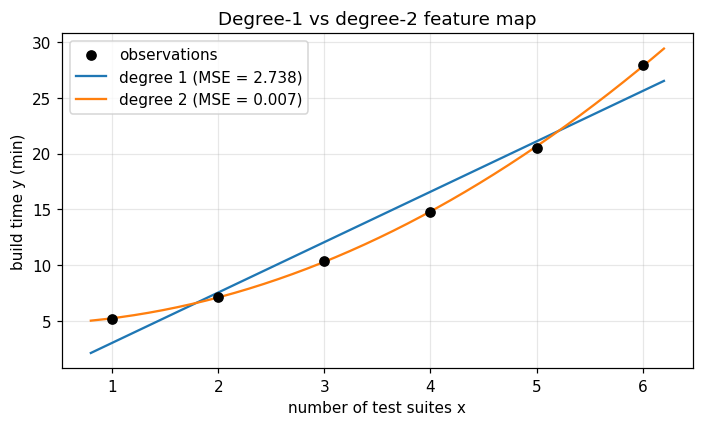

In [3]:
# Data
x = np.array(list(range(1, 7)), dtype=float)
y = np.array([5.2, 7.1, 10.4, 14.8, 20.5, 27.9], dtype=float)

# a) Degree-1 model vs. feature map phi(x) = [1, x, x^2]^T  (still linear in the parameters)
def fit_poly(x, y, degree):
    Phi = np.vander(x, degree + 1, increasing=True)      # columns: 1, x, x^2, ...
    beta = np.linalg.lstsq(Phi, y, rcond=None)[0]
    return beta, Phi @ beta

beta1, yhat1 = fit_poly(x, y, 1)
beta2, yhat2 = fit_poly(x, y, 2)
mse1 = np.mean((y - yhat1) ** 2)
mse2 = np.mean((y - yhat2) ** 2)
print(f"degree 1: beta = {np.round(beta1, 3)}  MSE = {mse1:.3f}")
print(f"degree 2: beta = {np.round(beta2, 3)}  MSE = {mse2:.3f}   (exact value {mse2:.2e})")
print("residuals degree 1:", np.round(y - yhat1, 3))
print("residuals degree 2:", np.round(y - yhat2, 3))

xs = np.linspace(x.min() - 0.2, x.max() + 0.2, 200)
plt.figure(figsize=(6.5, 4))
plt.scatter(x, y, color="black", zorder=3, label="observations")
plt.plot(xs, beta1[0] + beta1[1] * xs, label=f"degree 1 (MSE = {mse1:.3f})")
plt.plot(xs, beta2[0] + beta2[1] * xs + beta2[2] * xs ** 2, label=f"degree 2 (MSE = {mse2:.3f})")
plt.xlabel("number of test suites x"); plt.ylabel("build time y (min)"); plt.title("Degree-1 vs degree-2 feature map")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

**a) Result.** Degree 1: MSE = 2.738; degree 2 (feature map φ(x) = [1, x, x²]ᵀ): MSE = 0.007. The residuals of the straight line have a systematic **+ − +** pattern (under-prediction at both ends, over-prediction in the middle) — the signature of ignored curvature, which the x² term removes. Both models are still *linear in the parameters*, so ordinary least squares applies. A lower training MSE is guaranteed for the larger (nested) model, so the evidence that degree 2 is genuinely better is the visible curvature in the data, not the MSE alone.

stability bound: alpha < 0.0659; chosen alpha = 0.01
beta after GD = 4.173   closed form = 4.173
loss: start = 267.218, after 10 it = 3.358, final = 3.167
loss non-increasing: True
loss change < 1e-6 first reached at iteration 27


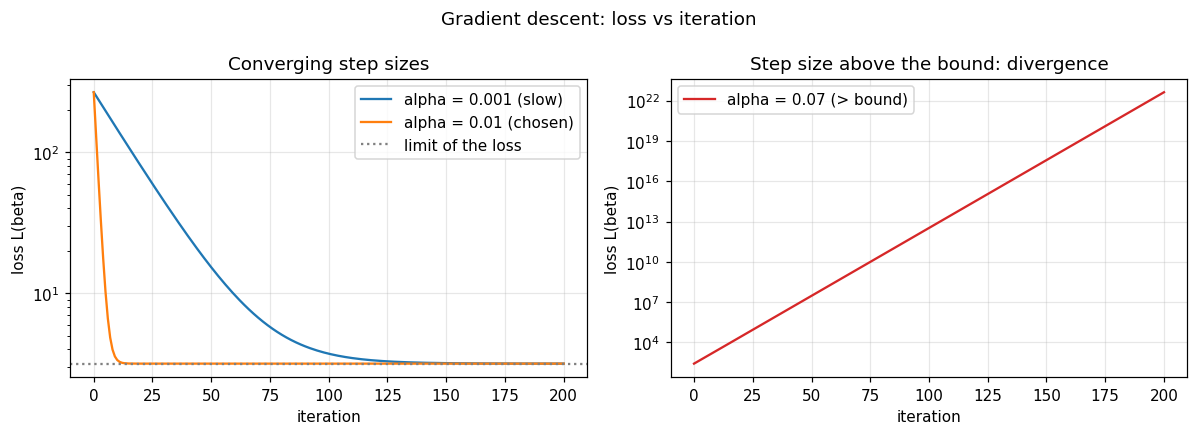

In [4]:
# b) Gradient descent for y_hat = beta * x  (no intercept)
def gradient_descent(x, y, alpha, iters=200, beta=0.0):
    losses = []
    for _ in range(iters):
        losses.append(np.mean((y - beta * x) ** 2))                  # L(beta)
        grad = -2 / len(x) * np.sum(x * (y - beta * x))              # dL/dbeta
        beta = beta - alpha * grad
    losses.append(np.mean((y - beta * x) ** 2))
    return beta, np.array(losses)

# Stability bound for this quadratic loss: L'' = 2*mean(x^2)  ->  need alpha < 2 / L''
alpha_max = 2 / (2 * np.mean(x ** 2))
alpha = 0.01                                                         # chosen step size
beta_gd, losses = gradient_descent(x, y, alpha)
beta_closed = np.sum(x * y) / np.sum(x ** 2)                         # closed-form optimum

print(f"stability bound: alpha < {alpha_max:.4f}; chosen alpha = {alpha}")
print(f"beta after GD = {beta_gd:.3f}   closed form = {beta_closed:.3f}")
print(f"loss: start = {losses[0]:.3f}, after 10 it = {losses[10]:.3f}, final = {losses[-1]:.3f}")
print("loss non-increasing:", bool(np.all(np.diff(losses) <= 1e-12)))
k = next((i for i in range(1, len(losses)) if abs(losses[i] - losses[i - 1]) < 1e-6), None)
print(f"loss change < 1e-6 first reached at iteration {k}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for a, lab in [(0.001, "alpha = 0.001 (slow)"), (alpha, f"alpha = {alpha} (chosen)")]:
    _, l = gradient_descent(x, y, a)
    axes[0].plot(l, label=lab)
axes[0].axhline(losses[-1], color="gray", ls=":", label="limit of the loss")
axes[0].set_title("Converging step sizes")
_, l_big = gradient_descent(x, y, 0.07)
axes[1].semilogy(l_big, color="C3", label="alpha = 0.07 (> bound)")
axes[1].set_title("Step size above the bound: divergence")
for ax_ in axes:
    ax_.set_xlabel("iteration"); ax_.set_ylabel("loss L(beta)"); ax_.grid(alpha=0.3); ax_.legend()
axes[0].set_yscale("log")
plt.suptitle("Gradient descent: loss vs iteration"); plt.tight_layout(); plt.show()

**b) Convergence diagnosis.**
- With α = 0.01 the loss decreases monotonically and flattens out; β converges to **4.173**, identical to the closed-form optimum Σxy / Σx². ✔ Gradient descent **converges**.
- The loss does not go to zero: it settles at ≈ 3.167, which is even higher than the 2.738 of the line *with* an intercept, because ŷ = βx is forced through the origin while the data are curved and do not pass through it. Converging ≠ fitting well; the limit comes from the model, not from the optimiser.
- The step size matters: α must satisfy α < 2 / (2·mean(x²)) ≈ 0.066. α = 0.001 converges slowly; α = 0.07 is above the bound and **diverges** (the loss explodes).

## Part II — Logistic Regression
### Question 3 — Deployment failure
Features: change size *x₁* and test-failure rate *x₂*; *y* = 1 means FAIL.

**Think first.**
- **Why classification?** The target is a discrete label (FAIL = 1 / OK = 0) and we want a probability p(Y = 1 | x) between 0 and 1 — a linear regression output is unbounded and not a probability.
- **Signs of the coefficients:** both **positive** — the FAIL rows have larger change size and larger test-failure rate, so increasing either feature should increase the log-odds of failure.
- **Lowering the threshold:** we flag FAIL whenever p ≥ t, so a lower *t* flags more deployments → **fewer missed failures (FN ↓) but more false alarms (FP ↑)**.

In [5]:
# Data: columns are x1, x2; y = 1 means FAIL
X = np.array([(.2, .1), (.5, .2), (.7, .4), (1, .7), (1.3, .9), (1.5, 1.1), (1.8, 1.4), (2, 1.7)])
y = np.array([0, 0, 0, 0, 1, 1, 1, 1])

# a) Train the logistic model (sklearn default: L2 penalty, C = 1; see note below)
model = LogisticRegression(C=1.0).fit(X, y)
b0 = model.intercept_[0]
b1, b2 = model.coef_[0]
print(f"a) intercept = {b0:.3f}, coef x1 = {b1:.3f}, coef x2 = {b2:.3f}")

x_new = np.array([1.2, 0.8])
z = b0 + b1 * x_new[0] + b2 * x_new[1]
p_new = 1 / (1 + np.exp(-z))                      # p(Y=1|x) = sigma(z)
print(f"a) x = {x_new}: z = {z:.3f}, p(Y=1|x) = {p_new:.3f}")
assert np.isclose(p_new, model.predict_proba([x_new])[0, 1])

# b) Two thresholds (0.3 and 0.7) compared with the usual 0.5
p = model.predict_proba(X)[:, 1]
print("b) training probabilities:", np.round(p, 3))
for t in (0.3, 0.5, 0.7):
    pred = (p >= t).astype(int)
    cm = confusion_matrix(y, pred)                # [[TN, FP], [FN, TP]]
    print(f"\nthreshold = {t}: accuracy = {accuracy_score(y, pred):.3f}  "
          f"TN = {cm[0, 0]}, FP = {cm[0, 1]}, FN = {cm[1, 0]}, TP = {cm[1, 1]}")
    print(cm)

a) intercept = -1.831, coef x1 = 1.005, coef x2 = 0.869
a) x = [1.2 0.8]: z = 0.070, p(Y=1|x) = 0.518
b) training probabilities: [0.176 0.24  0.314 0.446 0.564 0.653 0.768 0.84 ]

threshold = 0.3: accuracy = 0.750  TN = 2, FP = 2, FN = 0, TP = 4
[[2 2]
 [0 4]]

threshold = 0.5: accuracy = 1.000  TN = 4, FP = 0, FN = 0, TP = 4
[[4 0]
 [0 4]]

threshold = 0.7: accuracy = 0.750  TN = 4, FP = 0, FN = 2, TP = 2
[[4 0]
 [2 2]]


**Comparison with the reasoning.**
- Both coefficients are positive (β₁ = 1.005, β₂ = 0.869), as predicted. The probability for x = [1.2, 0.8]ᵀ is **0.518** — just above 0.5, i.e. close to the decision boundary (it lies between the last OK point (1, 0.7) and the first FAIL point (1.3, 0.9)).
- Threshold trade-off: **t = 0.3** → FP = 2, FN = 0 (accuracy 0.750); **t = 0.5** → no errors (accuracy 1.000); **t = 0.7** → FP = 0, FN = 2 (accuracy 0.750). This matches the expectation: lowering the threshold removes missed failures but creates false alarms, raising it does the opposite. For deployments a missed failure is usually costlier than a false alarm, which argues for the lower threshold.

### Question 4 — Logistic loss and one update
x = [1, 2, 1.5]ᵀ, y = 1, β⁽⁰⁾ = [0.1, −0.2, 0.3]ᵀ.

**Think first.**
- For *y* = 1 the loss is −log p, so a probability **near 1** gives the lower loss (→ 0); a probability near 0 gives a very large loss.
- After a correct gradient-descent step (small enough learning rate) the **loss should decrease**, and since *y* = 1 the predicted probability should **move up toward 1**.

In [6]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def logistic_loss(y, p):
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

x = np.array([1, 2, 1.5])
y = 1
beta0 = np.array([0.1, -0.2, 0.3])

# a) forward pass
z = beta0 @ x
p = sigmoid(z)
loss0 = logistic_loss(y, p)
print(f"a) z = {z:.3f}, p = {p:.3f}, loss = {loss0:.3f}")

# b) one gradient-descent step (learning rate 0.1)
grad = (p - y) * x
beta1 = beta0 - 0.1 * grad
z1 = beta1 @ x
p1 = sigmoid(z1)
loss1 = logistic_loss(y, p1)
print(f"b) gradient = {np.round(grad, 3)}")
print(f"b) beta(1)  = {np.round(beta1, 3)}")
print(f"b) z = {z1:.3f}, p = {p1:.3f}, loss = {loss1:.3f}")
print(f"loss decreased: {loss1 < loss0};  p moved from {p:.3f} to {p1:.3f} (target y = {y})")

a) z = 0.150, p = 0.537, loss = 0.621
b) gradient = [-0.463 -0.925 -0.694]
b) beta(1)  = [ 0.146 -0.107  0.369]
b) z = 0.485, p = 0.619, loss = 0.480
loss decreased: True;  p moved from 0.537 to 0.619 (target y = 1)


**Comparison.** Before the step z = 0.150, p = 0.537, ℓ = 0.621. The gradient (p − y)·x = [−0.463, −0.925, −0.694] is negative in every component, so subtracting it *increases* every coefficient and therefore raises z. After the step z = 0.485, p = 0.619, ℓ = 0.480: the probability moved toward 1 and the loss dropped — exactly as expected.

## Part III — Softmax Regression
### Question 5 — Softmax outputs
Logits for **Frontend, Backend, Database** (4 incidents).

**Think first.**
- **Predicted classes** (largest logit per row): row 1 → Backend (2.1); row 2 → Frontend (2.4); row 3 → Database (2.2); row 4 → Frontend (1.5), but the logits 1.5 / 1.4 / 1.3 are almost equal, so I expect a *near-uniform, low-confidence* output there.
- **Two properties of a valid probability vector:** every entry is **non-negative** (0 ≤ pₖ ≤ 1) and the entries **sum to 1**.
- **Adding the same constant c to all logits of a row:** it should **not change** the probabilities, because e^(z+c) = e^c · e^z and the factor e^c cancels between numerator and denominator (shift invariance — the reason the stable version subtracts the row maximum).

In [7]:
CLASSES = ["Frontend", "Backend", "Database"]
Z = np.array([[1.2, 2.1, 0.4], [2.4, 0.8, 0.5], [0.3, 1.1, 2.2], [1.5, 1.4, 1.3]])

def softmax(Z):
    """Numerically stable row-wise softmax: subtract the row maximum first."""
    Z = np.atleast_2d(Z)
    Z = Z - Z.max(axis=1, keepdims=True)       # does not change the result, avoids overflow
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

P = softmax(Z)
print("a) probabilities (rows = samples):")
print(np.round(P, 3))
pred = P.argmax(axis=1)
for i, k in enumerate(pred):
    print(f"   row {i + 1}: predicted {CLASSES[k]:<16} p = {P[i, k]:.3f}")
print("argmax of probabilities == argmax of logits:", bool(np.all(pred == Z.argmax(axis=1))))

# Why 'stable'? A naive softmax overflows for large logits.
with np.errstate(all="ignore"):
    naive = np.exp(Z + 1000) / np.exp(Z + 1000).sum(axis=1, keepdims=True)
print("naive softmax on Z + 1000, row 1 :", naive[0])
print("stable softmax on Z + 1000, row 1:", np.round(softmax(Z + 1000)[0], 3))

a) probabilities (rows = samples):
[[0.256 0.629 0.115]
 [0.74  0.149 0.111]
 [0.101 0.225 0.675]
 [0.367 0.332 0.301]]
   row 1: predicted Backend          p = 0.629
   row 2: predicted Frontend         p = 0.740
   row 3: predicted Database         p = 0.675
   row 4: predicted Frontend         p = 0.367
argmax of probabilities == argmax of logits: True
naive softmax on Z + 1000, row 1 : [nan nan nan]
stable softmax on Z + 1000, row 1: [0.256 0.629 0.115]


In [8]:
# b) Row sums and valid-probability checks
print("b) row sums:", np.round(P.sum(axis=1), 3))
print("   all p in [0, 1]:", bool(np.all((P >= 0) & (P <= 1))))

# Experiment: add the same constant c to every logit of every row
for c in (5.0, -3.0, 100.0):
    P_c = softmax(Z + c)
    print(f"   c = {c:>6}: max |softmax(Z + c) - softmax(Z)| = {np.abs(P_c - P).max():.3e}")
print("   probabilities after adding c = 5:")
print(np.round(softmax(Z + 5.0), 3))

b) row sums: [1. 1. 1. 1.]
   all p in [0, 1]: True
   c =    5.0: max |softmax(Z + c) - softmax(Z)| = 1.110e-16
   c =   -3.0: max |softmax(Z + c) - softmax(Z)| = 5.551e-17
   c =  100.0: max |softmax(Z + c) - softmax(Z)| = 2.109e-15
   probabilities after adding c = 5:
[[0.256 0.629 0.115]
 [0.74  0.149 0.111]
 [0.101 0.225 0.675]
 [0.367 0.332 0.301]]


**Comparison.** The `argmax` of the probabilities gives exactly the predicted classes (Backend, Frontend, Database, Frontend). Row 4 is nearly uniform (≈ 0.367 / 0.332 / 0.301) as expected. All row sums equal 1.000 and all entries lie in [0, 1]. Adding a constant changes the probabilities by at most ~10⁻¹⁵ (floating-point round-off) — i.e. not at all — even for c = 100, and the stable version also handles logits around 1000 where the naive formula returns `nan`.

### Question 6 — Multiclass incident classification
Features: normalized error rate *x₁* and database latency *x₂*; classes 0 = Frontend, 1 = Backend, 2 = Database.

**Think first.**
- **Why binary logistic regression is insufficient:** it outputs a single probability p(Y = 1 | x) and separates only two outcomes. Here there are **three mutually exclusive classes**, so we need a probability for *each* class, summing to 1 — that is what softmax provides.
- **Number of outputs for one sample:** **3** class probabilities (Frontend, Backend, Database).
- **Confusions to inspect first:** **Frontend ↔ Backend**. Both have low database latency (x₂ ≤ 0.9) and their error rates are adjacent (x₁ ≈ 0.8–1.1 vs 1.4–1.6), so they are the closest pair in feature space; Database is clearly separated by its high x₂ (≈ 1.4–1.7), so I expect it to be recognised easily.

In [9]:
CLASSES = ["Frontend", "Backend", "Database"]
X = np.array([(.9, .2), (1.1, .3), (.8, .4), (1.4, .8), (1.6, .9), (1.5, .7), (.4, 1.5), (.5, 1.7), (.6, 1.4)])
y = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])

# a) Multiclass (softmax / multinomial) logistic regression
model = LogisticRegression(C=1.0, max_iter=1000).fit(X, y)
P = model.predict_proba(X)               # shape (9 samples, 3 classes)
pred = model.predict(X)
print("a) probabilities, predictions:")
for i in range(len(y)):
    print(f"   sample {i}: x = {X[i]}  true = {CLASSES[y[i]]:<12} P = {np.round(P[i], 3)}  -> {CLASSES[pred[i]]}")
cm = confusion_matrix(y, pred)
print("\nconfusion matrix (rows = true, columns = predicted):")
print(cm)
print(f"accuracy = {accuracy_score(y, pred):.3f}")

# b) Multiclass log loss: mean of -log(p_c), c = true class
p_true = P[np.arange(len(y)), y]
per_sample = -np.log(p_true)
print("\nb) p_c per sample      :", np.round(p_true, 3))
print("   -log(p_c) per sample:", np.round(per_sample, 3))
print(f"   mean log loss = {per_sample.mean():.3f}   (sklearn log_loss = {log_loss(y, P):.3f})")
i, j = per_sample.argmax(), per_sample.argmin()
print(f"   largest contribution : sample {i}, p_c = {p_true[i]:.3f}  ->  -log(p_c) = {per_sample[i]:.3f}")
print(f"   smallest contribution: sample {j}, p_c = {p_true[j]:.3f}  ->  -log(p_c) = {per_sample[j]:.3f}")

# c) Coefficient matrix: one row (weight vector) per class
W, b = model.coef_, model.intercept_
print("\nc) coefficient matrix W, shape", W.shape, "(classes x features):")
print(np.round(W, 3))
print("   intercepts b, shape", b.shape, ":", np.round(b, 3))
print("   softmax(X W^T + b) reproduces predict_proba:", bool(np.allclose(softmax(X @ W.T + b), P)))

a) probabilities, predictions:
   sample 0: x = [0.9 0.2]  true = Frontend     P = [0.589 0.267 0.144]  -> Frontend
   sample 1: x = [1.1 0.3]  true = Frontend     P = [0.52  0.338 0.142]  -> Frontend
   sample 2: x = [0.8 0.4]  true = Frontend     P = [0.534 0.263 0.203]  -> Frontend
   sample 3: x = [1.4 0.8]  true = Backend      P = [0.307 0.496 0.197]  -> Backend
   sample 4: x = [1.6 0.9]  true = Backend      P = [0.248 0.575 0.177]  -> Backend
   sample 5: x = [1.5 0.7]  true = Backend      P = [0.317 0.524 0.159]  -> Backend
   sample 6: x = [0.4 1.5]  true = Database     P = [0.167 0.158 0.675]  -> Database
   sample 7: x = [0.5 1.7]  true = Database     P = [0.124 0.164 0.712]  -> Database
   sample 8: x = [0.6 1.4]  true = Database     P = [0.195 0.214 0.591]  -> Database

confusion matrix (rows = true, columns = predicted):
[[3 0 0]
 [0 3 0]
 [0 0 3]]
accuracy = 1.000

b) p_c per sample      : [0.589 0.52  0.534 0.496 0.575 0.524 0.675 0.712 0.591]
   -log(p_c) per sample: [

**Comparison and interpretation.**
- **a)** All 9 training samples are classified correctly (diagonal confusion matrix, accuracy 1.000). The least confident predictions are indeed Frontend/Backend samples (e.g. sample 3, the Backend point (1.4, 0.8), has p_c = 0.496) — the pair I expected to be hardest — while Database samples get p_c ≈ 0.6–0.7.
- **b)** Log loss = **0.552** = mean of −log p_c. Each sample contributes −log of the probability given to its *true* class: p_c = 1 would cost 0, p_c = 0.5 costs 0.693, and p_c → 0 costs ∞. Sample 3 contributes the most (0.701 for p_c = 0.496). Accuracy is perfect but the loss is not close to 0 because the L2 penalty keeps probabilities moderate — log loss measures *confidence*, accuracy does not.
- **c)** The coefficient matrix **W has shape 3 × 2** (classes × features), plus an intercept vector of length 3. Each class needs its **own parameter vector** because the score zₖ = wₖ·x + bₖ measures how much the input looks like class *k*, and different classes respond to different features: Backend is driven by x₁ (w = [1.002, 0.042]), Database by x₂ (w = [−0.727, 0.970]), Frontend is pushed by *low* x₂ (w = [−0.276, −1.012]). With one shared vector all scores would be equal and every probability would be 1/3. (Strictly only K − 1 vectors are identifiable, since adding the same vector to all rows leaves the probabilities unchanged; regularisation fixes this ambiguity.)

---
# VARIANT V2 (Variant B)

## Part I — Linear Regression
### Question 1 — Bug-resolution effort
Number of files changed *x* and bug-resolution time *y* (hours).

**Think first.**
- **(i) Input / target:** input *x* = number of files changed; target *y* = bug-resolution time in hours.
- **(ii) Sign of the slope:** **positive** — touching more files means more code to understand, change and test, so resolution takes longer. Each extra file should add on the order of (9.0 − 2.4) / 7 ≈ 0.94 h.
- **(iii) Which prediction is safer?** *x* = 5.5 is inside the observed range [1, 8] (interpolation) and should be trusted more. *x* = 12 lies 50 % beyond the largest observed value (extrapolation): large multi-file changes may behave differently (coordination, integration problems), so the straight line may not hold.

a) beta0 = 1.196, beta1 = 0.987
b) prediction at x = 5.5: 6.624   [inside the training range 1..8]
b) prediction at x = 12: 13.039   [OUTSIDE (extrapolation) the training range 1..8]
b) MSE = 0.019, R^2 = 0.996


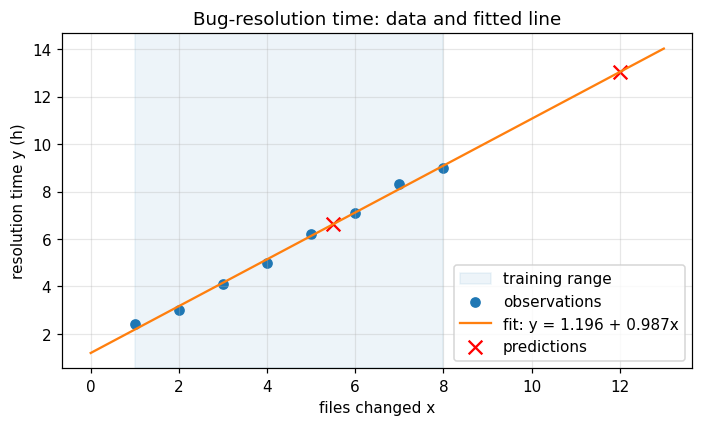

In [10]:
# Data
x = np.array(list(range(1, 9)), dtype=float)
y = np.array([2.4, 3.0, 4.1, 5.0, 6.2, 7.1, 8.3, 9.0], dtype=float)
points = [5.5, 12]

# a) Fit y_hat = b0 + b1*x with the normal equations (X^T X) b = X^T y
X = np.column_stack([np.ones_like(x), x])
b0, b1 = np.linalg.solve(X.T @ X, X.T @ y)
print(f"a) beta0 = {b0:.3f}, beta1 = {b1:.3f}")

# b) Predictions, MSE and R^2
yhat = X @ np.array([b0, b1])
mse = np.mean((y - yhat) ** 2)
r2 = 1 - np.sum((y - yhat) ** 2) / np.sum((y - y.mean()) ** 2)
for xn in points:
    where = "inside" if x.min() <= xn <= x.max() else "OUTSIDE (extrapolation)"
    print(f"b) prediction at x = {xn}: {b0 + b1 * xn:.3f}   [{where} the training range {x.min():.0f}..{x.max():.0f}]")
print(f"b) MSE = {mse:.3f}, R^2 = {r2:.3f}")

xs = np.linspace(0, 13, 100)
plt.figure(figsize=(6.5, 4))
plt.axvspan(x.min(), x.max(), alpha=0.08, color="C0", label="training range")
plt.scatter(x, y, label="observations")
plt.plot(xs, b0 + b1 * xs, color="C1", label=f"fit: y = {b0:.3f} + {b1:.3f}x")
plt.scatter(points, [b0 + b1 * p for p in points], marker="x", color="red", s=80, label="predictions")
plt.xlabel("files changed x"); plt.ylabel("resolution time y (h)"); plt.title("Bug-resolution time: data and fitted line")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

**c) Comparison with the initial reasoning.**
- **Slope:** β₁ = 0.987 > 0 — positive as predicted and close to the rough estimate of 0.94 h per file. *Interpretation:* each additional changed file adds ≈ 0.987 h (≈ 59 min) of resolution time. β₀ = 1.196 h is the baseline effort (triage, reproduction) when no extra files are involved; *x* = 0 is outside the data, so treat it as the intercept of the line.
- **Predictions:** ŷ(5.5) = 6.624 h lies between the observed 6.2 (x = 5) and 7.1 (x = 6) — reliable. ŷ(12) = 13.039 h is an extrapolation far from the data; although R² = 0.996 and MSE = 0.019 show an excellent fit on [1, 8], they cannot validate *x* = 12, so it is the less trustworthy prediction — as expected.

### Question 2 — API memory usage and model complexity
Concurrent requests *x* (hundreds) and memory usage *y* (GB).

**Think first.**
- **Linear or curved?** Consecutive differences of *y* are 0.6, 1.1, 1.6, 2.1, 2.6 — they increase by a constant 0.5 each step, so the relationship is **curved**, and the constant *second* difference suggests a **quadratic** shape (memory grows faster than the load).
- **More flexible model, lower training error, worse on unseen requests:** extra flexibility lets the model fit not only the signal but also the noise of the few points it has seen (high variance). Between and beyond those points it can oscillate or extrapolate wildly, so on *new* request levels its error can be larger than that of a simpler model. Training error alone cannot reveal this; held-out data can.

degree 1: beta = [-0.633  1.6  ]  MSE = 0.389
degree 2: beta = [ 1.7  -0.15  0.25]  MSE = 0.000   (exact value 1.67e-29)
residuals degree 1: [ 0.833 -0.167 -0.667 -0.667 -0.167  0.833]
residuals degree 2: [-0.  0.  0.  0.  0.  0.]


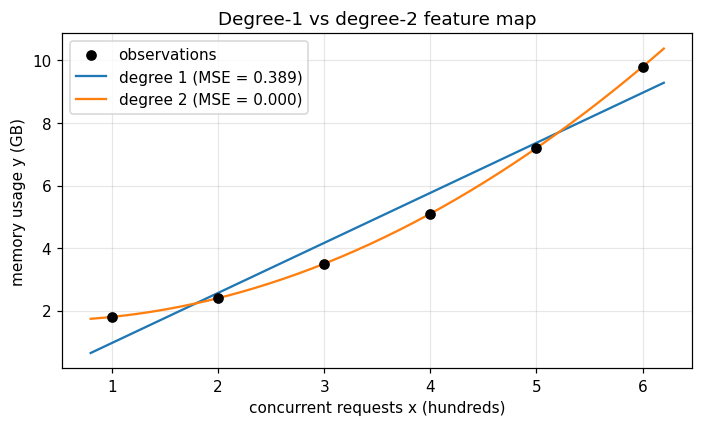

In [11]:
# Data
x = np.array(list(range(1, 7)), dtype=float)
y = np.array([1.8, 2.4, 3.5, 5.1, 7.2, 9.8], dtype=float)

# a) Degree-1 model vs. feature map phi(x) = [1, x, x^2]^T  (still linear in the parameters)
def fit_poly(x, y, degree):
    Phi = np.vander(x, degree + 1, increasing=True)      # columns: 1, x, x^2, ...
    beta = np.linalg.lstsq(Phi, y, rcond=None)[0]
    return beta, Phi @ beta

beta1, yhat1 = fit_poly(x, y, 1)
beta2, yhat2 = fit_poly(x, y, 2)
mse1 = np.mean((y - yhat1) ** 2)
mse2 = np.mean((y - yhat2) ** 2)
print(f"degree 1: beta = {np.round(beta1, 3)}  MSE = {mse1:.3f}")
print(f"degree 2: beta = {np.round(beta2, 3)}  MSE = {mse2:.3f}   (exact value {mse2:.2e})")
print("residuals degree 1:", np.round(y - yhat1, 3))
print("residuals degree 2:", np.round(y - yhat2, 3))

xs = np.linspace(x.min() - 0.2, x.max() + 0.2, 200)
plt.figure(figsize=(6.5, 4))
plt.scatter(x, y, color="black", zorder=3, label="observations")
plt.plot(xs, beta1[0] + beta1[1] * xs, label=f"degree 1 (MSE = {mse1:.3f})")
plt.plot(xs, beta2[0] + beta2[1] * xs + beta2[2] * xs ** 2, label=f"degree 2 (MSE = {mse2:.3f})")
plt.xlabel("concurrent requests x (hundreds)"); plt.ylabel("memory usage y (GB)"); plt.title("Degree-1 vs degree-2 feature map")
plt.grid(alpha=0.3); plt.legend(); plt.tight_layout(); plt.show()

**a) Result.** Degree 1: MSE = 0.389; degree 2 with φ(x) = [1, x, x²]ᵀ: MSE = 0.000 (≈ 10⁻²⁹, floating-point zero). The fitted coefficients are exactly [1.7, −0.15, 0.25], i.e. these data follow y = 1.7 − 0.15x + 0.25x² exactly, which also confirms the constant second difference (2 × 0.25 = 0.5). The straight line shows the typical **+ − +** residual pattern of ignored curvature. Here a zero training error is legitimate because the true pattern is quadratic; with noisy data a model reaching zero training error would signal over-fitting, which is why the fit must be judged on unseen data.

stability bound: alpha < 0.0659; chosen alpha = 0.01
beta after GD = 1.454   closed form = 1.454
loss: start = 32.523, after 10 it = 0.489, final = 0.466
loss non-increasing: True
loss change < 1e-6 first reached at iteration 24


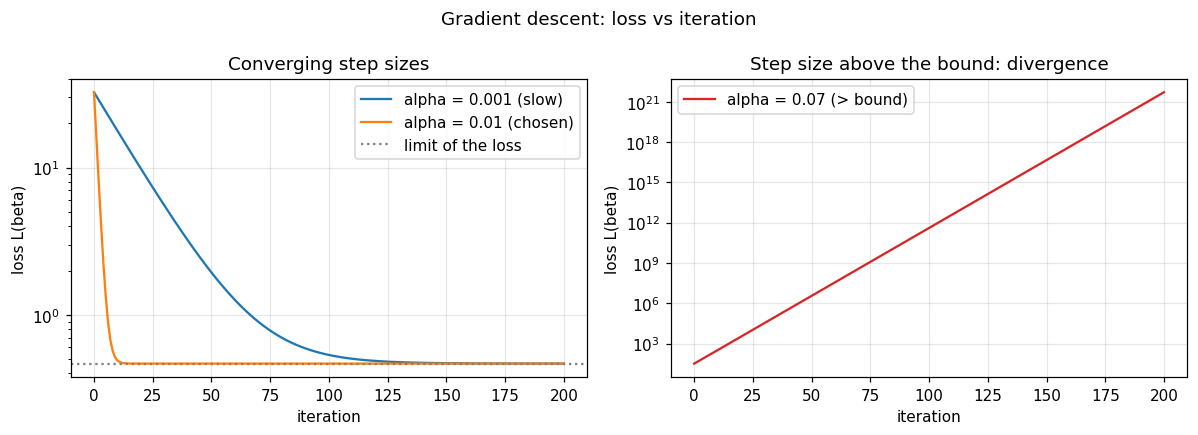

In [12]:
# b) Gradient descent for y_hat = beta * x  (no intercept)
def gradient_descent(x, y, alpha, iters=200, beta=0.0):
    losses = []
    for _ in range(iters):
        losses.append(np.mean((y - beta * x) ** 2))                  # L(beta)
        grad = -2 / len(x) * np.sum(x * (y - beta * x))              # dL/dbeta
        beta = beta - alpha * grad
    losses.append(np.mean((y - beta * x) ** 2))
    return beta, np.array(losses)

# Stability bound for this quadratic loss: L'' = 2*mean(x^2)  ->  need alpha < 2 / L''
alpha_max = 2 / (2 * np.mean(x ** 2))
alpha = 0.01                                                         # chosen step size
beta_gd, losses = gradient_descent(x, y, alpha)
beta_closed = np.sum(x * y) / np.sum(x ** 2)                         # closed-form optimum

print(f"stability bound: alpha < {alpha_max:.4f}; chosen alpha = {alpha}")
print(f"beta after GD = {beta_gd:.3f}   closed form = {beta_closed:.3f}")
print(f"loss: start = {losses[0]:.3f}, after 10 it = {losses[10]:.3f}, final = {losses[-1]:.3f}")
print("loss non-increasing:", bool(np.all(np.diff(losses) <= 1e-12)))
k = next((i for i in range(1, len(losses)) if abs(losses[i] - losses[i - 1]) < 1e-6), None)
print(f"loss change < 1e-6 first reached at iteration {k}")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
for a, lab in [(0.001, "alpha = 0.001 (slow)"), (alpha, f"alpha = {alpha} (chosen)")]:
    _, l = gradient_descent(x, y, a)
    axes[0].plot(l, label=lab)
axes[0].axhline(losses[-1], color="gray", ls=":", label="limit of the loss")
axes[0].set_title("Converging step sizes")
_, l_big = gradient_descent(x, y, 0.07)
axes[1].semilogy(l_big, color="C3", label="alpha = 0.07 (> bound)")
axes[1].set_title("Step size above the bound: divergence")
for ax_ in axes:
    ax_.set_xlabel("iteration"); ax_.set_ylabel("loss L(beta)"); ax_.grid(alpha=0.3); ax_.legend()
axes[0].set_yscale("log")
plt.suptitle("Gradient descent: loss vs iteration"); plt.tight_layout(); plt.show()

**b) Convergence diagnosis.**
- With α = 0.01 the loss decreases monotonically and flattens out; β converges to **1.454**, identical to the closed-form optimum Σxy / Σx². ✔ Gradient descent **converges**.
- The final loss (≈ 0.466) is above zero — and above the 0.389 of the degree-1 line with intercept — because ŷ = βx has no intercept and cannot represent the curved data. The optimiser converged; the model is the limitation.
- Step size: the bound is α < 2 / (2·mean(x²)) ≈ 0.066. α = 0.001 converges slowly, α = 0.01 quickly, and α = 0.07 exceeds the bound and **diverges**.

## Part II — Logistic Regression
### Question 3 — Flaky-test prediction
Standardized features: execution-time variation *x₁* and recent failure rate *x₂*; *y* = 1 means FLAKY.

**Think first.**
- **Why classification?** The target is a category (FLAKY / not flaky) and we want a probability p(Y = 1 | x) ∈ [0, 1], not an unbounded number.
- **Signs of the coefficients:** both **positive** — flaky tests are the ones with larger timing variation and a higher recent failure rate, so each feature raises the log-odds of FLAKY.
- **Increasing the threshold:** a test is flagged only if p ≥ t, so a higher *t* flags fewer tests → **fewer false alarms (FP ↓) but more missed flaky tests (FN ↑)**.

In [13]:
# Data: columns are x1, x2; y = 1 means FLAKY
X = np.array([(.1, .2), (.3, .2), (.5, .4), (.7, .5), (1.0, .9), (1.2, 1.1), (1.5, 1.3), (1.8, 1.6)])
y = np.array([0, 0, 0, 0, 1, 1, 1, 1])

# a) Train the logistic model (sklearn default: L2 penalty, C = 1; see note below)
model = LogisticRegression(C=1.0).fit(X, y)
b0 = model.intercept_[0]
b1, b2 = model.coef_[0]
print(f"a) intercept = {b0:.3f}, coef x1 = {b1:.3f}, coef x2 = {b2:.3f}")

x_new = np.array([0.9, 0.8])
z = b0 + b1 * x_new[0] + b2 * x_new[1]
p_new = 1 / (1 + np.exp(-z))                      # p(Y=1|x) = sigma(z)
print(f"a) x = {x_new}: z = {z:.3f}, p(Y=1|x) = {p_new:.3f}")
assert np.isclose(p_new, model.predict_proba([x_new])[0, 1])

# b) Two thresholds (0.3 and 0.7) compared with the usual 0.5
p = model.predict_proba(X)[:, 1]
print("b) training probabilities:", np.round(p, 3))
for t in (0.3, 0.5, 0.7):
    pred = (p >= t).astype(int)
    cm = confusion_matrix(y, pred)                # [[TN, FP], [FN, TP]]
    print(f"\nthreshold = {t}: accuracy = {accuracy_score(y, pred):.3f}  "
          f"TN = {cm[0, 0]}, FP = {cm[0, 1]}, FN = {cm[1, 0]}, TP = {cm[1, 1]}")
    print(cm)

a) intercept = -1.569, coef x1 = 0.975, coef x2 = 0.931
a) x = [0.9 0.8]: z = 0.054, p(Y=1|x) = 0.513
b) training probabilities: [0.217 0.252 0.33  0.396 0.561 0.651 0.751 0.842]

threshold = 0.3: accuracy = 0.750  TN = 2, FP = 2, FN = 0, TP = 4
[[2 2]
 [0 4]]

threshold = 0.5: accuracy = 1.000  TN = 4, FP = 0, FN = 0, TP = 4
[[4 0]
 [0 4]]

threshold = 0.7: accuracy = 0.750  TN = 4, FP = 0, FN = 2, TP = 2
[[4 0]
 [2 2]]


**Comparison with the reasoning.**
- Both coefficients are positive (β₁ = 0.975, β₂ = 0.931), as predicted. For x = [0.9, 0.8]ᵀ the flaky probability is **0.513** — barely above 0.5, which makes sense because this point lies between the last stable test (0.7, 0.5) and the first flaky one (1.0, 0.9), i.e. at the decision boundary.
- Threshold trade-off: **t = 0.3** → FP = 2, FN = 0 (accuracy 0.750); **t = 0.5** → no errors (accuracy 1.000); **t = 0.7** → FP = 0, FN = 2 (accuracy 0.750). Increasing the threshold removed the false alarms but let two flaky tests slip through — exactly the predicted trade-off. If flaky tests are expensive to miss, a lower threshold is preferable.

### Question 4 — Logistic loss and one update
x = [1, 1.5, 2]ᵀ, y = 0, β⁽⁰⁾ = [0.2, 0.1, −0.1]ᵀ.

**Think first.**
- For *y* = 0 the loss is −log(1 − p), so a probability **near 0** gives the lower loss; a probability near 1 is penalised heavily.
- After a correct gradient-descent update the predicted probability should **move down toward 0** (and the loss should decrease).

In [14]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def logistic_loss(y, p):
    return -(y * np.log(p) + (1 - y) * np.log(1 - p))

x = np.array([1, 1.5, 2])
y = 0
beta0 = np.array([0.2, 0.1, -0.1])

# a) forward pass
z = beta0 @ x
p = sigmoid(z)
loss0 = logistic_loss(y, p)
print(f"a) z = {z:.3f}, p = {p:.3f}, loss = {loss0:.3f}")

# b) one gradient-descent step (learning rate 0.1)
grad = (p - y) * x
beta1 = beta0 - 0.1 * grad
z1 = beta1 @ x
p1 = sigmoid(z1)
loss1 = logistic_loss(y, p1)
print(f"b) gradient = {np.round(grad, 3)}")
print(f"b) beta(1)  = {np.round(beta1, 3)}")
print(f"b) z = {z1:.3f}, p = {p1:.3f}, loss = {loss1:.3f}")
print(f"loss decreased: {loss1 < loss0};  p moved from {p:.3f} to {p1:.3f} (target y = {y})")

a) z = 0.150, p = 0.537, loss = 0.771
b) gradient = [0.537 0.806 1.075]
b) beta(1)  = [ 0.146  0.019 -0.207]
b) z = -0.240, p = 0.440, loss = 0.580
loss decreased: True;  p moved from 0.537 to 0.440 (target y = 0)


**Comparison.** Before the step z = 0.150, p = 0.537, ℓ = 0.771 — the model leans the wrong way (it gives > 0.5 to class 1 although y = 0). The gradient (p − y)·x = [0.537, 0.806, 1.075] is positive, so subtracting it pushes z down. After the step z = −0.240, p = 0.440, ℓ = 0.580: the probability moved toward 0 and the loss dropped, as expected.

## Part III — Softmax Regression
### Question 5 — Issue-type probabilities
Logits for **Bug, Feature Request, Documentation** (4 issues).

**Think first.**
- **Predicted classes** (largest logit per row): row 1 → Bug (2.0); row 2 → Feature Request (2.2); row 3 → Documentation (2.4); row 4 → Feature Request (1.5), though 1.3 / 1.5 / 1.2 are close, so I expect low confidence there.
- **Two properties of a valid probability vector:** all entries are **non-negative** (0 ≤ pₖ ≤ 1) and they **sum to 1**.
- **Multiplying the logits of a row by 2:** the predicted class (argmax) stays the same because multiplication by a positive number preserves the order, but the probabilities themselves **will change** — the gaps between logits double, so the distribution becomes sharper (more confident), like lowering a temperature. So the probabilities are *not* preserved.

In [15]:
CLASSES = ["Bug", "Feature Request", "Documentation"]
Z = np.array([[2.0, 0.8, 0.4], [0.6, 2.2, 0.7], [0.5, 1.0, 2.4], [1.3, 1.5, 1.2]])

def softmax(Z):
    """Numerically stable row-wise softmax: subtract the row maximum first."""
    Z = np.atleast_2d(Z)
    Z = Z - Z.max(axis=1, keepdims=True)       # does not change the result, avoids overflow
    E = np.exp(Z)
    return E / E.sum(axis=1, keepdims=True)

P = softmax(Z)
print("a) probabilities (rows = samples):")
print(np.round(P, 3))
pred = P.argmax(axis=1)
for i, k in enumerate(pred):
    print(f"   row {i + 1}: predicted {CLASSES[k]:<16} p = {P[i, k]:.3f}")
print("argmax of probabilities == argmax of logits:", bool(np.all(pred == Z.argmax(axis=1))))

# Why 'stable'? A naive softmax overflows for large logits.
with np.errstate(all="ignore"):
    naive = np.exp(Z + 1000) / np.exp(Z + 1000).sum(axis=1, keepdims=True)
print("naive softmax on Z + 1000, row 1 :", naive[0])
print("stable softmax on Z + 1000, row 1:", np.round(softmax(Z + 1000)[0], 3))

a) probabilities (rows = samples):
[[0.665 0.2   0.134]
 [0.142 0.702 0.157]
 [0.107 0.177 0.716]
 [0.32  0.391 0.289]]
   row 1: predicted Bug              p = 0.665
   row 2: predicted Feature Request  p = 0.702
   row 3: predicted Documentation    p = 0.716
   row 4: predicted Feature Request  p = 0.391
argmax of probabilities == argmax of logits: True
naive softmax on Z + 1000, row 1 : [nan nan nan]
stable softmax on Z + 1000, row 1: [0.665 0.2   0.134]


In [16]:
# b) Row sums and valid-probability checks
print("b) row sums:", np.round(P.sum(axis=1), 3))
print("   all p in [0, 1]:", bool(np.all((P >= 0) & (P <= 1))))

# Experiment: multiply every row's logits by 2
P2 = softmax(2 * Z)
print("   row sums after scaling:", np.round(P2.sum(axis=1), 3))
print("   original probabilities:")
print(np.round(P, 3))
print("   probabilities after logits x 2:")
print(np.round(P2, 3))
print("   max |P2 - P| =", round(float(np.abs(P2 - P).max()), 3))
print("   same predicted class for every row:", bool(np.all(P2.argmax(axis=1) == P.argmax(axis=1))))
print("   top probability per row, before -> after:", np.round(P.max(axis=1), 3), "->", np.round(P2.max(axis=1), 3))

b) row sums: [1. 1. 1. 1.]
   all p in [0, 1]: True
   row sums after scaling: [1. 1. 1. 1.]
   original probabilities:
[[0.665 0.2   0.134]
 [0.142 0.702 0.157]
 [0.107 0.177 0.716]
 [0.32  0.391 0.289]]
   probabilities after logits x 2:
[[0.884 0.08  0.036]
 [0.037 0.917 0.046]
 [0.021 0.056 0.923]
 [0.302 0.451 0.247]]
   max |P2 - P| = 0.219
   same predicted class for every row: True
   top probability per row, before -> after: [0.665 0.702 0.716 0.391] -> [0.884 0.917 0.923 0.451]


**Comparison.** The `argmax` gives exactly the predicted classes (Bug, Feature Request, Documentation, Feature Request). Every row sums to 1.000 with all entries in [0, 1]. Doubling the logits keeps every predicted class but changes the probabilities (max difference ≈ 0.219): the top probability becomes larger in every row, e.g. row 1: 0.665 → 0.884 and the uncertain row 4: 0.391 → 0.451. So the experiment confirms the prediction — *classes preserved, probabilities not*. The stable implementation also works for logits around 1000, where the naive formula produces `nan`.

### Question 6 — Service root-cause classification
Features: normalized timeout rate *x₁* and database latency *x₂*; classes 0 = Application, 1 = Network, 2 = Database.

**Think first.**
- **Why one binary logistic model is insufficient:** a binary model produces a single probability p(Y = 1 | x) and separates two outcomes only. There are **three** mutually exclusive root causes, so we need one probability per class, summing to 1 (softmax).
- **Outputs for one input:** **3** class probabilities (Application, Network, Database).
- **Most useful feature for Database incidents:** **database latency x₂** — Database samples have x₂ ≈ 1.4–1.6, whereas all other samples have x₂ ≤ 0.6; a low x₁ also helps a little.

In [17]:
CLASSES = ["Application", "Network", "Database"]
X = np.array([(.8, .3), (1.0, .4), (.9, .2), (1.5, .5), (1.7, .6), (1.6, .4), (.3, 1.4), (.4, 1.6), (.5, 1.5)])
y = np.array([0, 0, 0, 1, 1, 1, 2, 2, 2])

# a) Multiclass (softmax / multinomial) logistic regression
model = LogisticRegression(C=1.0, max_iter=1000).fit(X, y)
P = model.predict_proba(X)               # shape (9 samples, 3 classes)
pred = model.predict(X)
print("a) probabilities, predictions:")
for i in range(len(y)):
    print(f"   sample {i}: x = {X[i]}  true = {CLASSES[y[i]]:<12} P = {np.round(P[i], 3)}  -> {CLASSES[pred[i]]}")
cm = confusion_matrix(y, pred)
print("\nconfusion matrix (rows = true, columns = predicted):")
print(cm)
print(f"accuracy = {accuracy_score(y, pred):.3f}")

# b) Multiclass log loss: mean of -log(p_c), c = true class
p_true = P[np.arange(len(y)), y]
per_sample = -np.log(p_true)
print("\nb) p_c per sample      :", np.round(p_true, 3))
print("   -log(p_c) per sample:", np.round(per_sample, 3))
print(f"   mean log loss = {per_sample.mean():.3f}   (sklearn log_loss = {log_loss(y, P):.3f})")
i, j = per_sample.argmax(), per_sample.argmin()
print(f"   largest contribution : sample {i}, p_c = {p_true[i]:.3f}  ->  -log(p_c) = {per_sample[i]:.3f}")
print(f"   smallest contribution: sample {j}, p_c = {p_true[j]:.3f}  ->  -log(p_c) = {per_sample[j]:.3f}")

# c) Coefficient matrix: one row (weight vector) per class
W, b = model.coef_, model.intercept_
print("\nc) coefficient matrix W, shape", W.shape, "(classes x features):")
print(np.round(W, 3))
print("   intercepts b, shape", b.shape, ":", np.round(b, 3))
print("   softmax(X W^T + b) reproduces predict_proba:", bool(np.allclose(softmax(X @ W.T + b), P)))

a) probabilities, predictions:
   sample 0: x = [0.8 0.3]  true = Application  P = [0.528 0.278 0.193]  -> Application
   sample 1: x = [1.  0.4]  true = Application  P = [0.464 0.346 0.19 ]  -> Application
   sample 2: x = [0.9 0.2]  true = Application  P = [0.537 0.306 0.158]  -> Application
   sample 3: x = [1.5 0.5]  true = Network      P = [0.33  0.534 0.136]  -> Network
   sample 4: x = [1.7 0.6]  true = Network      P = [0.266 0.611 0.123]  -> Network
   sample 5: x = [1.6 0.4]  true = Network      P = [0.325 0.568 0.108]  -> Network
   sample 6: x = [0.3 1.4]  true = Database     P = [0.207 0.11  0.683]  -> Database
   sample 7: x = [0.4 1.6]  true = Database     P = [0.159 0.11  0.73 ]  -> Database
   sample 8: x = [0.5 1.5]  true = Database     P = [0.184 0.138 0.678]  -> Database

confusion matrix (rows = true, columns = predicted):
[[3 0 0]
 [0 3 0]
 [0 0 3]]
accuracy = 1.000

b) p_c per sample      : [0.528 0.464 0.537 0.534 0.611 0.568 0.683 0.73  0.678]
   -log(p_c) per 

**Comparison and interpretation.**
- **a)** All 9 samples are classified correctly (diagonal confusion matrix, accuracy 1.000). Database samples receive p_c ≈ 0.68–0.73, Network ≈ 0.53–0.61 and Application ≈ 0.46–0.54; the Application samples are the least certain, because Application and Network are both low in x₂ and are separated only by x₁.
- **b)** Log loss = **0.533**, the mean of −log p_c. A sample's contribution is the negative log of the probability given to its true class: p_c = 1 → 0, p_c = 0.5 → 0.693, p_c → 0 → ∞. The largest contribution is sample 1 (Application, p_c = 0.464 → 0.769); the smallest is sample 7 (Database, p_c = 0.730 → 0.314). Despite 100 % accuracy the loss is not near 0 because the L2 penalty keeps probabilities moderate — log loss measures confidence, accuracy does not.
- **c)** The coefficient matrix **W is 3 × 2** (classes × features) with an intercept vector of length 3. The Database row is [−0.709, **1.008**]: the large positive weight on x₂ confirms the prediction that database latency identifies Database incidents. Network is driven by timeout rate x₁ (w = [1.063, −0.181]) and Application by low values of both features (w = [−0.354, −0.827]). A **separate parameter vector per class** is needed because each class has its own "profile" over the features; the score zₖ = wₖ·x + bₖ measures how well *x* matches class *k*, and softmax compares the three scores. A single shared vector would give identical scores and a uniform 1/3 output. (Only K − 1 vectors are strictly identifiable; regularisation resolves this redundancy.)